In [147]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("centrifuge line datasets.parquet")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
pf = pq.ParquetFile(DATA_PATH)
display(pd.DataFrame({"column": pf.schema_arrow.names,
                      "parquet_type": [str(f.type) for f in pf.schema_arrow]}))
print(f"Rows: {pf.metadata.num_rows:,}; file size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")
df = pq.read_table(DATA_PATH).to_pandas()

,column,parquet_type
0,date,"timestamp[ns, tz=UTC]"
1,Motor DE_Z Short Wave High Frequency,list<element: double>
2,Motor DE_Z Long Wave High Frequency,list<element: double>
3,Motor DE_X Short Wave Low Frequency,list<element: double>
4,Motor DE_Y Short Wave Low Frequency,list<element: double>
5,Motor DE_Z Short Wave Low Frequency,list<element: double>
6,Motor DE_Temperature,list<element: double>
7,Motor DE_Z Short Wave Low Frequency RMS,double
8,Motor DE_X Short Wave Low Frequency RMS,double
9,Motor DE_Y Short Wave Low Frequency RMS,double


Rows: 26,502; file size: 499.8 MiB


In [148]:


# Load dataset
DATA_PATH = Path("centrifuge line datasets.parquet")
df = pq.read_table(DATA_PATH).to_pandas()

# Ensure date is datetime in UTC
df["date"] = pd.to_datetime(df["date"], utc=True)

# 1. Bearing Fault: Jan 1, 2025 00:00 – Jan 4, 2025 23:00
# Inclusive of the entire 23:00 hour
bearing_mask = (
    (df["date"] >= "2025-01-01 00:00:00+00:00") &
    (df["date"] <  "2025-01-05 00:00:00+00:00")
)

# 2. Final Test: Apr 29, 2025 – Jun 9, 2025
# Inclusive of the entire June 9
final_test_mask = (
    (df["date"] >= "2025-04-29 00:00:00+00:00") &
    (df["date"] <  "2025-06-10 00:00:00+00:00")
)

# 3. Remaining data
remaining_mask = ~(bearing_mask | final_test_mask)

# Split datasets
df_bearing = df.loc[bearing_mask].copy()
df_final_test = df.loc[final_test_mask].copy()
df_remaining = df.loc[remaining_mask].copy()

# Save as Parquet
df_bearing.to_parquet("bearing_fault.parquet", index=False)
df_final_test.to_parquet("final_test.parquet", index=False)
df_remaining.to_parquet("remaining_data.parquet", index=False)

# Summary
for name, subset in [
    ("Bearing Fault", df_bearing),
    ("Final Test", df_final_test),
    ("Remaining Data", df_remaining),
]:
    print(f"\n{name}")
    print(f"  Records: {len(subset):,}")
    print(f"  Start: {subset['date'].min()}")
    print(f"  End:   {subset['date'].max()}")

print(f"\nOriginal records: {len(df):,}")
print(f"Split records:    {len(df_bearing) + len(df_final_test) + len(df_remaining):,}")

assert len(df) == len(df_bearing) + len(df_final_test) + len(df_remaining)


Bearing Fault
  Records: 513
  Start: 2025-01-01 00:00:00+00:00
  End:   2025-01-04 16:00:00+00:00

Final Test
  Records: 10,523
  Start: 2025-04-29 00:00:00+00:00
  End:   2025-06-09 23:59:58+00:00

Remaining Data
  Records: 15,466
  Start: 2025-01-05 04:01:20+00:00
  End:   2025-04-28 23:59:58+00:00

Original records: 26,502
Split records:    26,502


In [149]:
def fill_missing_waveform_rms(df):
    channel_pairs = {
        "Motor DE_Z Short Wave High Frequency":
            "Motor DE_Z Short Wave High Frequency RMS",
        "Motor DE_Z Long Wave High Frequency":
            "Motor DE_Z Long Wave High Frequency RMS",
        "Motor DE_X Short Wave Low Frequency":
            "Motor DE_X Short Wave Low Frequency RMS",
        "Motor DE_Y Short Wave Low Frequency":
            "Motor DE_Y Short Wave Low Frequency RMS",
        "Motor DE_Z Short Wave Low Frequency":
            "Motor DE_Z Short Wave Low Frequency RMS",
    }

    def raw_rms(value):
        if value is None or np.isscalar(value):
            return np.nan

        samples = np.asarray(value, dtype=float).ravel()
        if samples.size == 0 or not np.isfinite(samples).all():
            return np.nan

        return float(np.sqrt(np.mean(np.square(samples))))

    summary = []

    for waveform_col, rms_col in channel_pairs.items():
        if waveform_col not in df.columns:
            continue

        if rms_col not in df.columns:
            df[rms_col] = np.nan

        positions = np.flatnonzero(df[rms_col].isna().to_numpy())

        calculated = np.array([
            raw_rms(df[waveform_col].iloc[position])
            for position in positions
        ], dtype=float)

        valid = np.isfinite(calculated)

        df.iloc[
            positions[valid], df.columns.get_loc(rms_col)
        ] = calculated[valid]

        summary.append({
            "RMS column": rms_col,
            "values filled": int(valid.sum()),
            "still missing": int(df[rms_col].isna().sum()),
        })

    return pd.DataFrame(summary)

In [150]:
summary = fill_missing_waveform_rms(df)
display(summary)

,RMS column,values filled,still missing
0,Motor DE_Z Short Wave High Frequency RMS,2602,4510
1,Motor DE_Z Long Wave High Frequency RMS,625,25877
2,Motor DE_X Short Wave Low Frequency RMS,2675,23692
3,Motor DE_Y Short Wave Low Frequency RMS,2671,23709
4,Motor DE_Z Short Wave Low Frequency RMS,2562,20584


In [151]:
def check_completeness(df):
    df = pf.read().to_pandas()

    results = []

    for col in df.columns:

        series = df[col]
        is_waveform = pa.types.is_list(
            pf.schema_arrow.field(col).type
        )

        missing = series.isna().sum()

        empty_arrays = 0
        arrays_with_nan = 0
        arrays_with_inf = 0
        min_length = None
        max_length = None

        if is_waveform:
            lengths = []

            for value in series.dropna():

                arr = np.asarray(value, dtype=float)

                lengths.append(len(arr))

                if len(arr) == 0:
                    empty_arrays += 1

                if np.isnan(arr).any():
                    arrays_with_nan += 1

                if np.isinf(arr).any():
                    arrays_with_inf += 1

            if lengths:
                min_length = min(lengths)
                max_length = max(lengths)

        else:
            # Scalar numeric columns
            if pd.api.types.is_numeric_dtype(series):
                arrays_with_inf = np.isinf(
                    series.dropna().to_numpy()
                ).sum()

        results.append({
            "Column": col,
            "Type": "Waveform" if is_waveform else "Scalar / Date",
            "Total Rows": len(series),
            "Missing": missing,
            "Missing %": round(missing / len(series) * 100, 2),
            "Empty Arrays": empty_arrays,
            "With NaN": arrays_with_nan,
            "With Inf": arrays_with_inf,
            "Min Samples": min_length,
            "Max Samples": max_length
        })

    completeness_df = pd.DataFrame(results)

    display(completeness_df)


def plot_waveforms(df, row_label):
    """Plot waveforms for an index label, not a row position."""
    if row_label not in df.index:
        raise KeyError(f"Index label {row_label} is not in this DataFrame.")
    if not df.index.is_unique:
        raise ValueError("The DataFrame index must have unique labels.")

    row = df.loc[row_label]

    wave_cols = [
        col for col in df.columns
        if ("Wave" in col and "RMS" not in col)
        or col == "Motor DE_Audio Signal"
    ]

    for col in wave_cols:
        value = row[col]
        if value is None or np.isscalar(value):
            continue

        waveform = np.asarray(value, dtype=float).ravel()
        if waveform.size == 0:
            continue

        plt.figure(figsize=(14, 3))
        plt.plot(np.arange(waveform.size), waveform, linewidth=0.6)
        plt.title(f"{col}\nIndex: {row_label} | {row.get('date', '')}")
        plt.xlabel("Sample index")
        plt.ylabel("Raw value (units unconfirmed)")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()



In [152]:
def get_nonempty_rows(df, columns=None):
    columns = list(df.columns) if columns is None else (
        [columns] if isinstance(columns, str) else list(columns)
    )

    def has_value(value):
        if isinstance(value, (list, tuple, np.ndarray)):
            values = np.asarray(value, dtype=object).ravel()
            return values.size > 0 and all(has_value(v) for v in values)

        if isinstance(value, str):
            return bool(value.strip())

        return not pd.isna(value)

    mask = pd.Series(True, index=df.index)

    for col in columns:
        mask &= df[col].map(has_value)

    return df.index[mask].tolist()

In [153]:
def compare_motor_temperatures(dfs, labels=None):
    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if len(labels) != len(dfs):
        raise ValueError("Provide one label per DataFrame.")

    groups = []
    for df in dfs:
        temperatures = []
        for value in df["Motor DE_Temperature"]:
            if value is None:
                continue

            values = np.asarray(value, dtype=float).ravel()
            if values.size and np.isfinite(values[0]):
                temperatures.append(values[0])

        groups.append(np.asarray(temperatures))

    fig, ax = plt.subplots(figsize=(9, 5))
    rng = np.random.default_rng(42)

    for position, (values, label) in enumerate(zip(groups, labels), start=1):
        if values.size == 0:
            ax.text(position, 0.5, "No temperature data",
                    transform=ax.get_xaxis_transform(), ha="center")
            continue

        ax.boxplot(
            values,
            positions=[position],
            widths=0.4,
            showfliers=False,
            medianprops={"color": "black", "linewidth": 2},
        )

        jitter = rng.uniform(-0.12, 0.12, size=values.size)
        ax.scatter(
            position + jitter, values,
            s=12, alpha=0.25, label=label,
        )

    ax.set_xticks(
        range(1, len(groups) + 1),
        [f"{label}\n(n={len(values):,})"
         for label, values in zip(labels, groups)],
    )
    ax.set_ylabel("Temperature (units unconfirmed)")
    ax.set_title("Motor temperature distributions")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [154]:
def plot_temperature_violin(dfs, labels=None):
    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if len(labels) != len(dfs):
        raise ValueError("Provide one label per DataFrame.")

    fig, ax = plt.subplots(figsize=(10, 5))
    rng = np.random.default_rng(42)
    tick_labels = []

    for position, (df, label) in enumerate(zip(dfs, labels), start=1):
        temperatures = []

        for value in df["Motor DE_Temperature"]:
            if value is None:
                continue

            values = np.asarray(value, dtype=float).ravel()
            if values.size and np.isfinite(values[0]):
                temperatures.append(values[0])

        temperatures = np.asarray(temperatures)
        tick_labels.append(f"{label}\n(n={temperatures.size:,})")

        if temperatures.size == 0:
            ax.text(
                position, 0.5, "No data",
                transform=ax.get_xaxis_transform(), ha="center",
            )
            continue

        # A density estimate needs at least two distinct values.
        if np.unique(temperatures).size > 1:
            violin = ax.violinplot(
                temperatures,
                positions=[position],
                widths=0.7,
                showmedians=True,
                showextrema=False,
            )
            violin["cmedians"].set_color("black")

        jitter = rng.uniform(-0.08, 0.08, temperatures.size)
        ax.scatter(
            position + jitter, temperatures,
            s=10, alpha=0.25,
        )

    ax.set_xticks(range(1, len(dfs) + 1), tick_labels)
    ax.set_ylabel("Temperature (units unconfirmed)")
    ax.set_title("Motor temperature distributions")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [155]:
def plot_rms_violin(dfs, labels=None):
    column = "Motor DE_Z Short Wave High Frequency RMS"

    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if len(labels) != len(dfs):
        raise ValueError("Provide one label per DataFrame.")

    fig, ax = plt.subplots(figsize=(10, 5))
    rng = np.random.default_rng(42)
    tick_labels = []

    for position, (df, label) in enumerate(zip(dfs, labels), start=1):
        values = pd.to_numeric(df[column], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan
        )
        values = values[np.isfinite(values)]

        tick_labels.append(f"{label}\n(n={values.size:,})")

        if values.size == 0:
            ax.text(
                position, 0.5, "No data",
                transform=ax.get_xaxis_transform(), ha="center",
            )
            continue

        if np.unique(values).size > 1:
            violin = ax.violinplot(
                values,
                positions=[position],
                widths=0.7,
                showmedians=True,
                showextrema=False,
            )
            violin["cmedians"].set_color("black")
        else:
            ax.hlines(values[0], position - 0.15, position + 0.15,
                      color="black")

        jitter = rng.uniform(-0.08, 0.08, values.size)
        ax.scatter(position + jitter, values, s=8, alpha=0.15)

    ax.set_xticks(range(1, len(dfs) + 1), tick_labels)
    ax.set_ylabel("RMS (units unconfirmed)")
    ax.set_title(column)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [156]:
def compare_waveforms(
    df1, index1, df2, index2,
    labels=("Dataset 1", "Dataset 2"),
):
    for df, index in [(df1, index1), (df2, index2)]:
        if index not in df.index:
            raise KeyError(f"Index label {index} is not in the DataFrame.")
        if not df.index.is_unique:
            raise ValueError("DataFrame indexes must be unique.")

    row1 = df1.loc[index1]
    row2 = df2.loc[index2]

    wave_cols = list(dict.fromkeys(
        col for df in (df1, df2) for col in df.columns
        if ("Wave" in col and "RMS" not in col)
        or col == "Motor DE_Audio Signal"
    ))

    for col in wave_cols:
        fig, axes = plt.subplots(
            1, 2, figsize=(16, 3), sharex=True, sharey=True
        )

        for ax, row, index, label in zip(
            axes, [row1, row2], [index1, index2], labels
        ):
            value = row.get(col)

            if value is None or np.isscalar(value):
                ax.text(
                    0.5, 0.5, "No waveform",
                    transform=ax.transAxes, ha="center",
                )
            else:
                waveform = np.asarray(value, dtype=float).ravel().copy()
                waveform[~np.isfinite(waveform)] = np.nan

                if waveform.size:
                    ax.plot(
                        np.arange(waveform.size),
                        waveform,
                        linewidth=0.6,
                    )
                else:
                    ax.text(
                        0.5, 0.5, "Empty waveform",
                        transform=ax.transAxes, ha="center",
                    )

            ax.set_title(
                f"{label} | Index: {index}\n{row.get('date', '')}"
            )
            ax.set_xlabel("Sample index")
            ax.grid(True, alpha=0.3)

        axes[0].set_ylabel("Raw value (units unconfirmed)")
        fig.suptitle(col)
        plt.tight_layout()
        plt.show()

In [157]:
def plot_rms_violin(dfs, column, labels=None):
    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if len(labels) != len(dfs):
        raise ValueError("Provide one label per DataFrame.")

    fig, ax = plt.subplots(figsize=(10, 5))
    rng = np.random.default_rng(42)
    tick_labels = []

    for position, (df, label) in enumerate(zip(dfs, labels), start=1):
        values = pd.to_numeric(df[column], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan
        )
        values = values[np.isfinite(values)]
        tick_labels.append(f"{label}\n(n={values.size:,})")

        if values.size == 0:
            ax.text(
                position, 0.5, "No data",
                transform=ax.get_xaxis_transform(), ha="center",
            )
            continue

        if np.unique(values).size > 1:
            violin = ax.violinplot(
                values,
                positions=[position],
                widths=0.7,
                showmedians=True,
                showextrema=False,
            )
            violin["cmedians"].set_color("black")
        else:
            ax.hlines(
                values[0], position - 0.15, position + 0.15,
                color="black",
            )

        jitter = rng.uniform(-0.08, 0.08, values.size)
        ax.scatter(position + jitter, values, s=8, alpha=0.15)

    ax.set_xticks(range(1, len(dfs) + 1), tick_labels)
    ax.set_ylabel("RMS (units unconfirmed)")
    ax.set_title(column)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [158]:
def plot_low_high_rms(dfs, labels=None):
    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if not dfs or len(labels) != len(dfs):
        raise ValueError("Provide DataFrames and one label per DataFrame.")

    low_col = "Motor DE_Z Short Wave Low Frequency RMS"
    high_col = "Motor DE_Z Short Wave High Frequency RMS"

    fig, axes = plt.subplots(
        len(dfs), 1,
        figsize=(15, 4 * len(dfs)),
        squeeze=False,
        sharey=True,
    )

    for ax, df, label in zip(axes[:, 0], dfs, labels):
        data = df.sort_index()

        low = pd.to_numeric(data[low_col], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan
        )
        high = pd.to_numeric(data[high_col], errors="coerce").to_numpy(
            dtype=float, na_value=np.nan
        )

        # Keep a row only if BOTH measurements are available.
        valid = np.isfinite(low) & np.isfinite(high)

        ax.scatter(
            data.index[valid], low[valid],
            s=8, alpha=0.5, label="Low-frequency RMS",
        )
        ax.scatter(
            data.index[valid], high[valid],
            s=8, alpha=0.5, label="High-frequency RMS",
        )

        ax.set_title(f"{label} — {valid.sum():,} matching rows")
        ax.set_xlabel("DataFrame index")
        ax.set_ylabel("RMS (units unconfirmed)")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

In [159]:
def plot_temperature_vs_rms(dfs, labels=None):
    """Plot rows where both temperature and high-frequency Z RMS exist."""
    if labels is None:
        labels = [f"DataFrame {i + 1}" for i in range(len(dfs))]

    if not dfs or len(labels) != len(dfs):
        raise ValueError("Provide DataFrames and one label per DataFrame.")

    rms_col = "Motor DE_Z Short Wave High Frequency RMS"

    def extract_temperature(value):
        if value is None:
            return np.nan

        values = np.asarray(value, dtype=float).ravel()
        return values[0] if values.size else np.nan

    fig, ax = plt.subplots(figsize=(10, 6))

    for df, label in zip(dfs, labels):
        if "Motor DE_Temperature" in df.columns:
            temperature = df["Motor DE_Temperature"].map(
                extract_temperature
            )
        elif "temperature_mean" in df.columns:
            temperature = df["temperature_mean"]
        else:
            raise ValueError(f"{label}: no temperature column found.")

        temperature = pd.to_numeric(
            temperature, errors="coerce"
        ).to_numpy(dtype=float, na_value=np.nan)

        rms = pd.to_numeric(
            df[rms_col], errors="coerce"
        ).to_numpy(dtype=float, na_value=np.nan)

        # Both values must be available in the same row.
        valid = np.isfinite(temperature) & np.isfinite(rms)

        ax.scatter(
            temperature[valid],
            rms[valid],
            s=20,
            alpha=0.5,
            label=f"{label} (n={valid.sum():,})",
        )

    ax.set_xlabel("Motor temperature (units unconfirmed)")
    ax.set_ylabel("High-frequency Z RMS (units unconfirmed)")
    ax.set_title("Motor temperature vs high-frequency Z RMS")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [160]:
def compare_reported_calculated_rms(df):
    wave_col = "Motor DE_Z Short Wave Low Frequency"
    rms_col = "Motor DE_Z Short Wave Low Frequency RMS"
    flag_col = f"{rms_col} calculated_from_raw"

    results = []

    for index, row in df.iterrows():
        # Exclude previously calculated values if provenance flags exist.
        if flag_col in df.columns and pd.notna(row[flag_col]):
            if bool(row[flag_col]):
                continue

        reported = pd.to_numeric(row[rms_col], errors="coerce")
        waveform = row[wave_col]

        if pd.isna(reported) or not np.isfinite(reported):
            continue
        if waveform is None or np.isscalar(waveform):
            continue

        samples = np.asarray(waveform, dtype=float).ravel()
        if samples.size == 0 or not np.isfinite(samples).all():
            continue

        calculated = float(np.sqrt(np.mean(np.square(samples))))
        if not np.isfinite(calculated):
            continue

        results.append({
            "row_index": index,
            "reported_rms": float(reported),
            "calculated_rms": calculated,
            "difference": calculated - float(reported),
        })

    comparison = pd.DataFrame(
        results,
        columns=[
            "row_index", "reported_rms",
            "calculated_rms", "difference",
        ],
    )

    if comparison.empty:
        print("No rows have both a valid waveform and reported RMS.")
        return comparison, pd.Series(dtype=float)

    differences = comparison["difference"]

    summary = pd.Series({
        "paired_rows": len(comparison),
        "mean_difference": differences.mean(),
        "difference_variance": differences.var(ddof=1),
        "difference_std": differences.std(ddof=1),
        "mean_absolute_difference": differences.abs().mean(),
    })

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].scatter(
        comparison["reported_rms"],
        comparison["calculated_rms"],
        s=15, alpha=0.5,
    )

    lower = comparison[["reported_rms", "calculated_rms"]].min().min()
    upper = comparison[["reported_rms", "calculated_rms"]].max().max()
    axes[0].plot([lower, upper], [lower, upper], "k--", label="Equal RMS")
    axes[0].set_xlabel("Reported RMS")
    axes[0].set_ylabel("Calculated raw RMS")
    axes[0].legend()

    axes[1].hist(differences, bins=40, edgecolor="white")
    axes[1].axvline(0, color="black", linestyle="--")
    axes[1].set_xlabel("Calculated − reported RMS")
    axes[1].set_ylabel("Number of rows")

    plt.tight_layout()
    plt.show()

    display(summary.to_frame("value"))
    return comparison, summary

In [161]:
df.shape

(26502, 18)

In [162]:
df.tail()

,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal,Motor DE_Z Long Wave High Frequency RMS
26497,2025-06-09 23:41:00+00:00,None,None,None,None,None,None,6.64155,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN
26498,2025-06-09 23:41:20+00:00,None,None,None,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,0.12582,NaN,NaN,None,NaN
26499,2025-06-09 23:51:00+00:00,None,None,None,None,None,None,NaN,NaN,NaN,2.09047,NaN,NaN,NaN,NaN,NaN,None,NaN
26500,2025-06-09 23:51:20+00:00,None,None,None,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,0.13775,NaN,NaN,None,NaN
26501,2025-06-09 23:59:58+00:00,None,None,None,None,None,None,NaN,NaN,NaN,NaN,5.52231,NaN,NaN,NaN,NaN,None,NaN


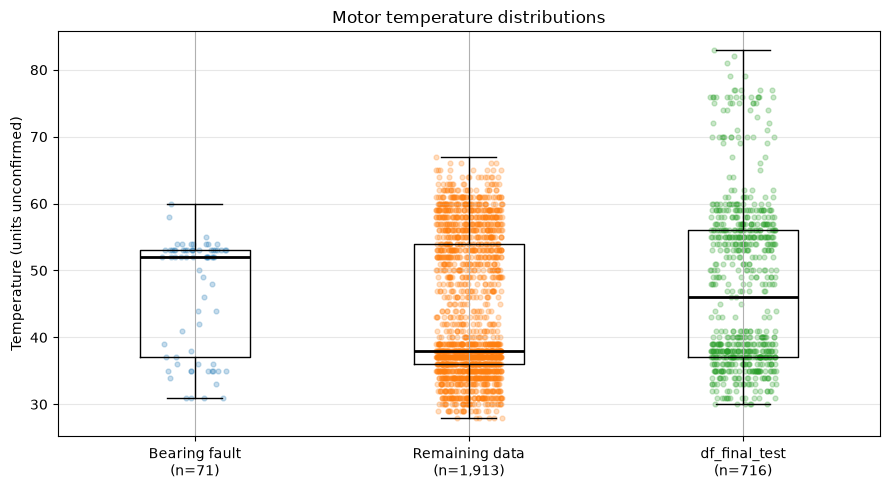

In [163]:
compare_motor_temperatures(
    [df_bearing, df_remaining,df_final_test],
    labels=["Bearing fault", "Remaining data","df_final_test"],
)


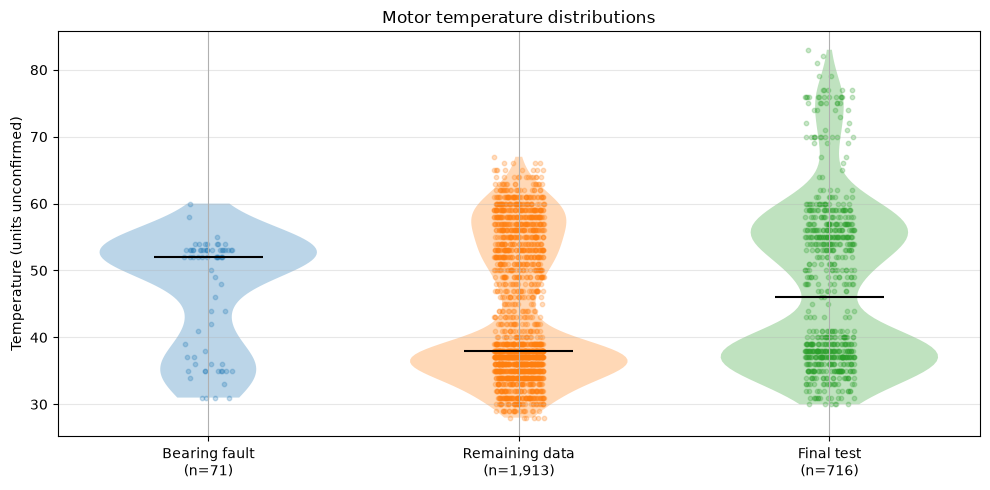

In [164]:
plot_temperature_violin(
    [df_bearing, df_remaining, df_final_test],
    labels=["Bearing fault", "Remaining data", "Final test"],
)

In [165]:
plot_rms_violin(
    [df_bearing, df_remaining, df_final_test],
    labels=["Bearing fault", "Remaining data", "Final test"],
)

TypeError: plot_rms_violin() missing 1 required positional argument: 'column'

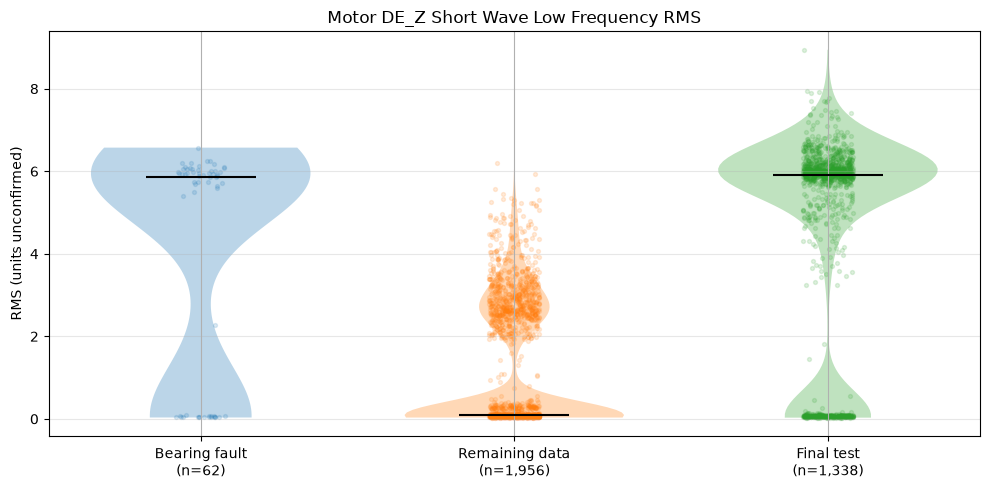

In [166]:
plot_rms_violin(
    [df_bearing, df_remaining, df_final_test],
    column="Motor DE_Z Short Wave Low Frequency RMS",
    labels=["Bearing fault", "Remaining data", "Final test"],
)

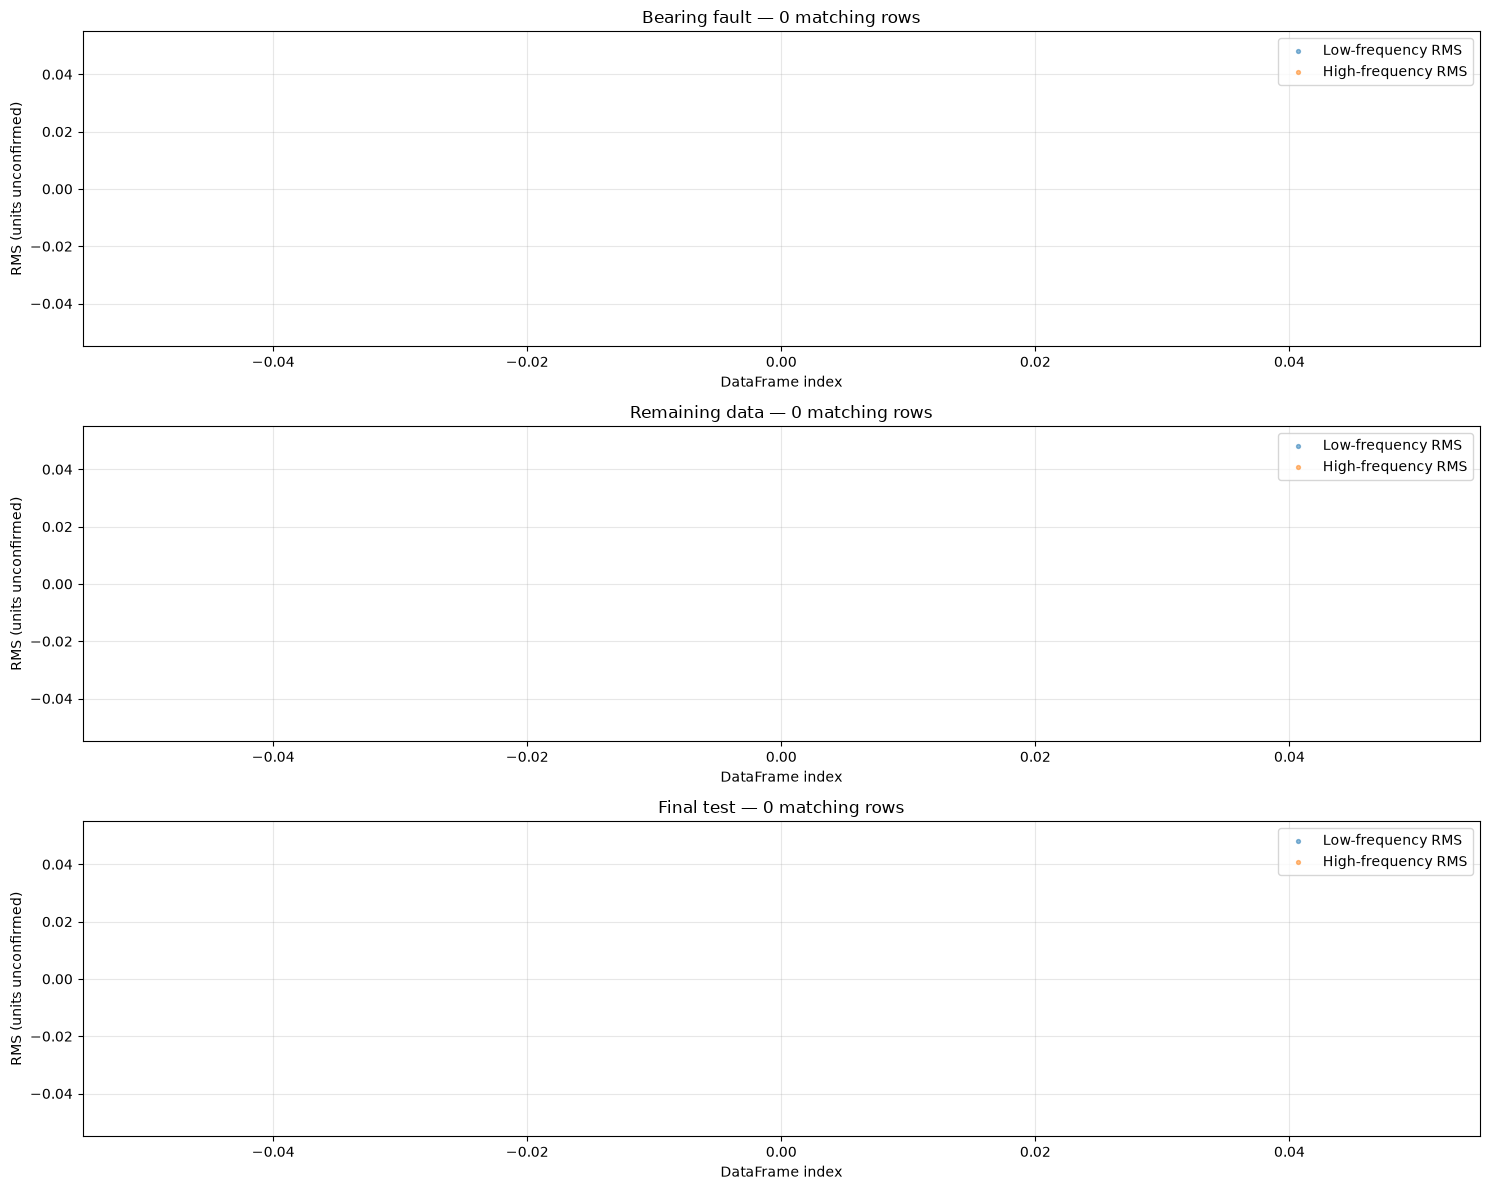

In [167]:
plot_low_high_rms(
    [df_bearing, df_remaining, df_final_test],
    labels=["Bearing fault", "Remaining data", "Final test"],
)

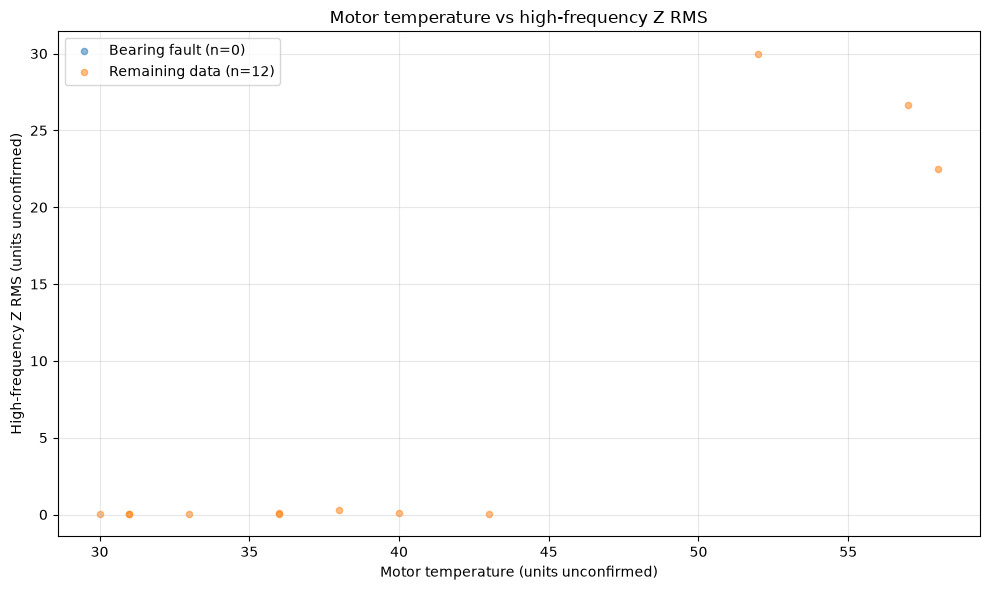

In [168]:
plot_temperature_vs_rms(
    [df_bearing, df_remaining],
    labels=["Bearing fault", "Remaining data"],
)

In [169]:
print(
    "Repeated index labels:",
    df_final_test.index.duplicated().sum()
)

print(
    "Repeated timestamps:",
    df_final_test["date"].duplicated().sum()
)

# Show all rows with repeated index labels
display(
    df_final_test.loc[
        df_final_test.index.duplicated(keep=False)
    ].sort_index()
)

Repeated index labels: 0
Repeated timestamps: 0


,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal


In [170]:
check_completeness(df_bearing)

,Column,Type,Total Rows,Missing,Missing %,Empty Arrays,With NaN,With Inf,Min Samples,Max Samples
0,date,Scalar / Date,26502,0,0.00,0,0,0,NaN,NaN
1,Motor DE_Z Short Wave High Frequency,Waveform,26502,23823,89.89,0,0,0,16384.0,16384.0
2,Motor DE_Z Long Wave High Frequency,Waveform,26502,25877,97.64,0,0,0,131072.0,131072.0
3,Motor DE_X Short Wave Low Frequency,Waveform,26502,23826,89.90,0,0,0,5120.0,5120.0
4,Motor DE_Y Short Wave Low Frequency,Waveform,26502,23824,89.90,0,0,0,5120.0,5120.0
5,Motor DE_Z Short Wave Low Frequency,Waveform,26502,23826,89.90,0,0,0,9216.0,9216.0
6,Motor DE_Temperature,Waveform,26502,23802,89.81,0,0,0,1.0,1.0
7,Motor DE_Z Short Wave Low Frequency RMS,Scalar / Date,26502,23146,87.34,0,0,0,NaN,NaN
8,Motor DE_X Short Wave Low Frequency RMS,Scalar / Date,26502,26367,99.49,0,0,0,NaN,NaN
9,Motor DE_Y Short Wave Low Frequency RMS,Scalar / Date,26502,26380,99.54,0,0,0,NaN,NaN


In [171]:
df_bearing[:10]

,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal
0,2025-01-01 00:00:00+00:00,"[0.07242919803775294, -0.009920802701344655, 0...",None,"[-0.015489234076085268, -0.0008492343586112838...","[0.06706568620575126, 0.08658568582904991, 0.0...","[0.031227949499022856, 0.014757949351203337, -...",[36.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,2025-01-01 01:00:00+00:00,"[0.08318234693797422, 0.09965234708579374, 0.0...",None,"[-0.10952263851140742, -0.02656264011238818, -...","[-0.03109570252490812, -0.011575702901609475, ...","[-0.08909455158088164, -0.07262455143306212, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2,2025-01-01 02:00:00+00:00,"[-0.04962009749124263, 0.1480199042825916, -0....",None,"[-0.07613276415577275, 0.016587234054895816, 0...","[0.08604335771451588, -0.006676640496152686, -...","[0.10445296968747186, 0.08798296953965234, -0....",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3,2025-01-01 03:00:00+00:00,"[0.09775443691250985, -0.050475564417865826, 0...",None,"[-0.04607120223590755, 0.012488796633988386, 0...","[0.04633426473083091, -0.017105734044889687, -...","[-0.07933514719641366, -0.04639514690077462, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
4,2025-01-01 04:00:00+00:00,"[-0.03739928500363021, 0.0614207158832869, 0.1...",None,"[0.09517334191332338, -0.012186656014819164, -...","[-0.05530317080774694, -0.0601831707135716, -0...","[0.06496678769245534, -0.000913212898822735, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
5,2025-01-01 05:00:00+00:00,"[0.07393908208450739, 0.10687908238014643, 0.1...",None,"[-0.02184848395336303, 0.04159151482235757, 0....","[0.05253243648621719, -0.06458756125357468, -0...","[0.07388267644435231, 0.057412676296532794, 0....",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
6,2025-01-01 06:00:00+00:00,"[0.07378829472963844, 0.007908294138360361, -0...",None,"[-0.020668515226134332, -0.0011485156028356869...","[0.02303321830549976, -0.006246781129448209, -...","[-0.01939728533034213, -0.0852772859216202, -0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
7,2025-01-01 07:00:00+00:00,"[0.13249885922141402, 0.08308885877795547, 0.0...",None,"[-0.10462834173085866, 0.012491656008933205, 0...","[0.017679515283816727, 0.046959514718764694, 0...","[-0.02785388696874236, 0.05449611377035524, 0....",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
8,2025-01-01 08:00:00+00:00,"[0.04145546484960505, 0.09086546529306361, 0.0...",None,"[-0.11506791965439334, -0.002827921820426127, ...","[0.10569202921033138, 0.027612030717136804, 0....","[0.030782959260655218, -0.0680370416262619, 0....",[34.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
9,2025-01-01 13:11:20+00:00,None,None,None,None,None,None,0.03595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


In [172]:
df_remaining.head()

,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal
513,2025-01-05 04:01:20+00:00,None,None,None,None,None,None,0.03344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
514,2025-01-05 04:11:21+00:00,None,None,None,None,None,None,NaN,NaN,NaN,0.05829,NaN,NaN,NaN,NaN,NaN,None
515,2025-01-05 04:21:20+00:00,None,None,None,None,None,None,NaN,NaN,NaN,NaN,0.02692,NaN,NaN,NaN,NaN,None
516,2025-01-05 04:41:20+00:00,None,None,None,None,None,None,NaN,0.0197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
517,2025-01-05 04:51:20+00:00,None,None,None,None,None,None,NaN,NaN,0.01968,NaN,NaN,NaN,NaN,NaN,NaN,None


In [ ]:
df.dtype()

AttributeError: 'DataFrame' object has no attribute 'dtype'

In [173]:
rows = get_nonempty_rows(
    df_bearing,
    columns=[
        "Motor DE_Z Short Wave Low Frequency RMS",
        "Motor DE_Z Short Wave Low Frequency"
    ],
)

print(rows)

# Display matching rows
display(df_bearing.loc[rows])

[]


,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal


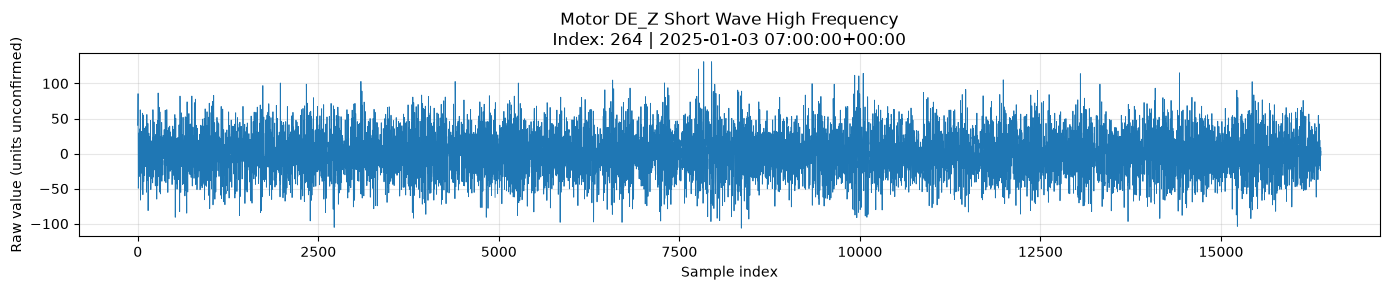

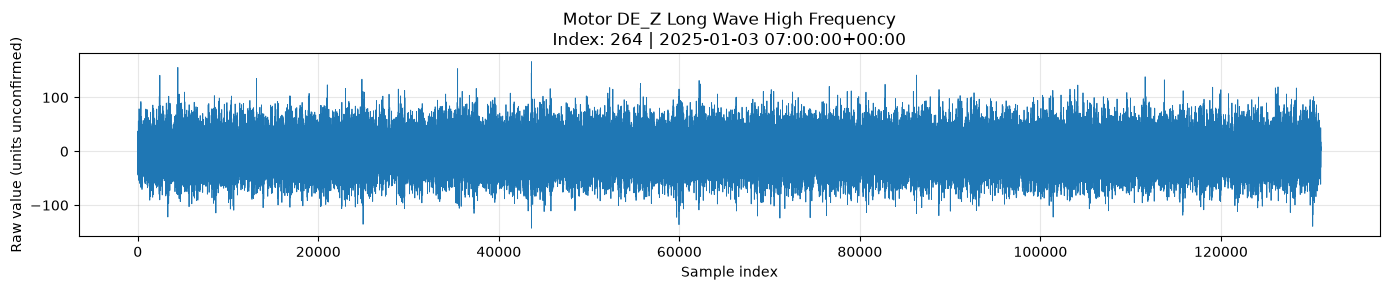

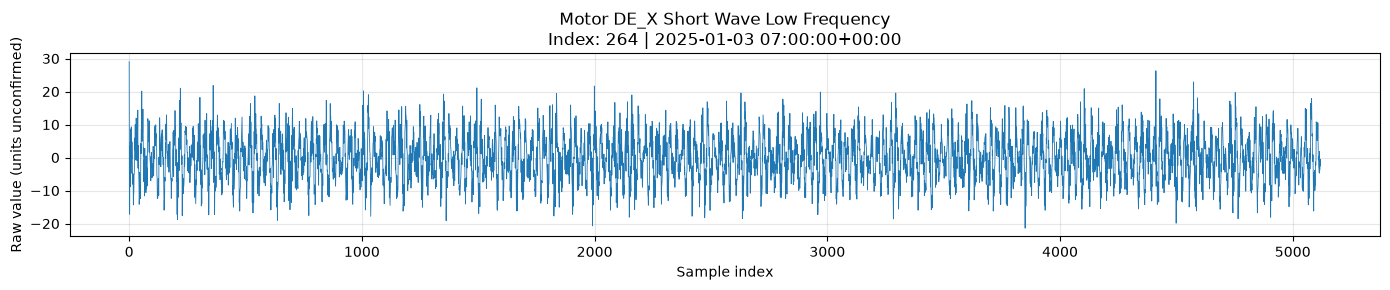

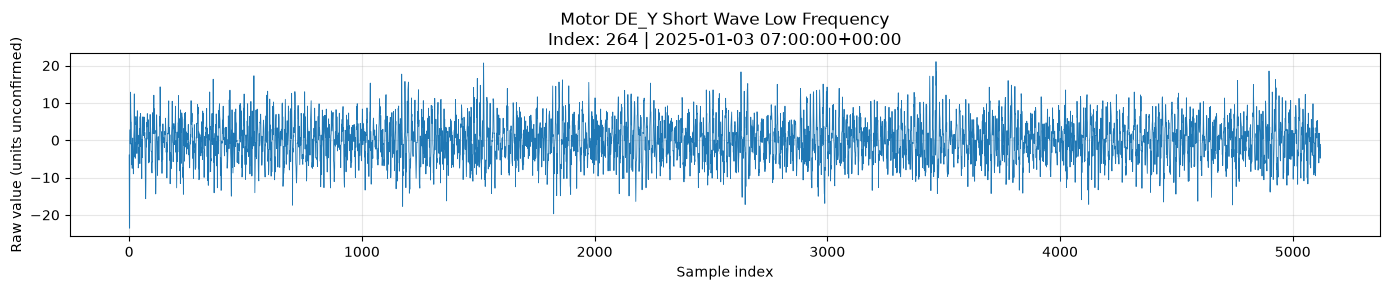

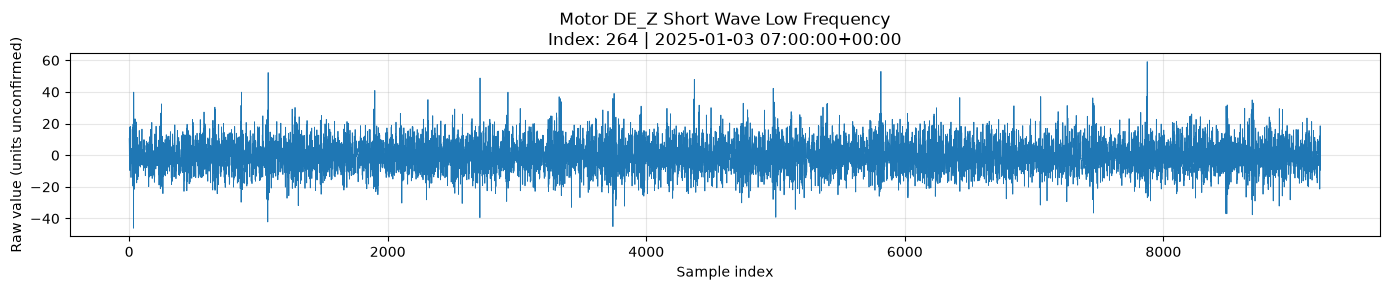

In [174]:
plot_waveforms(df_bearing,264)

In [ ]:
for i in df_bearing["Motor DE_Z Short Wave High Frequency"][264]:
    print(i)

40.30903361678156
46.369993671179145
66.80926385462317
84.74509401559862
85.45330402195486
31.942273541689246
-22.375786945819527
-49.41952718853918
-48.56308718085256
-46.86667716562715
-44.59381714522806
-7.948066816329629
7.138453319073051
13.512343376279205
20.87443344235453
0.18811325669321377
3.8609232896569665
-1.5906467592712943
-0.470686749219567
29.620003520846694
10.844203352332443
-10.435036838650376
-17.648896903395325
-27.234436989426285
-15.42544688343969
1.1269032651189264
28.0224135065082
35.13745357036623
9.510133340359062
-16.15012688994375
-32.91658704042402
-20.349976927637726
-7.453966811895043
21.121483444571822
62.32942381441626
49.68046370089087
-8.689216822981507
-59.087417275309235
-66.30127734005418
-9.002146825790078
32.09050354301962
18.667453422546714
4.700893297195762
2.0492232733968194
-4.752886787652642
-4.588186786174447
4.816183298230499
10.26775334715876
-1.425946757793099
-27.909706995486886
-27.662656993269593
-9.578596830963761
-3.138826773166329

In [175]:
signal = np.asarray(
    df.iloc[264]["Motor DE_Z Short Wave High Frequency"],
    dtype=float
)

rms = np.sqrt(np.mean(signal**2))

print("Peak acceleration:", np.max(np.abs(signal)))
print("RMS acceleration:", rms)
print("RMS if m/s², expressed in g:", rms / 9.80665)

Peak acceleration: 131.07520443141493
RMS acceleration: 30.971153417939583
RMS if m/s², expressed in g: 3.158178727489977


In [176]:
rows = get_nonempty_rows(
    df_final_test,
    columns=[
        "Motor DE_Z Short Wave High Frequency RMS",
        "Motor DE_Z Long Wave High Frequency"
    ],
)

print(rows)

# Display matching rows
display(df_remaining.loc[rows])


[21355, 21691, 23372, 24287, 24343, 26006]


KeyError: "None of [Index([21355, 21691, 23372, 24287, 24343, 26006], dtype='int64')] are in the [index]"

In [ ]:
def get_rms(data: np.ndarray) -> float:
    return float(np.sqrt(np.mean(np.square(data))))

In [ ]:
print(get_rms(df_remaining["Motor DE_Z Short Wave High Frequency"][9143]))


27.705413122900843


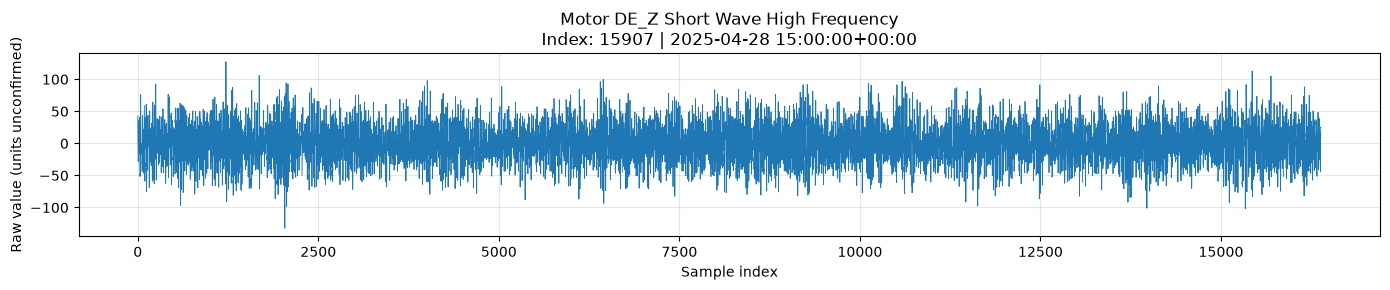

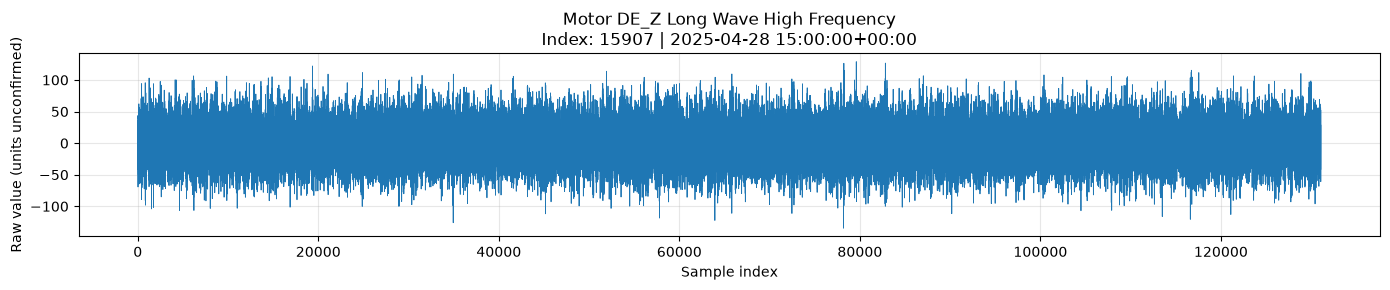

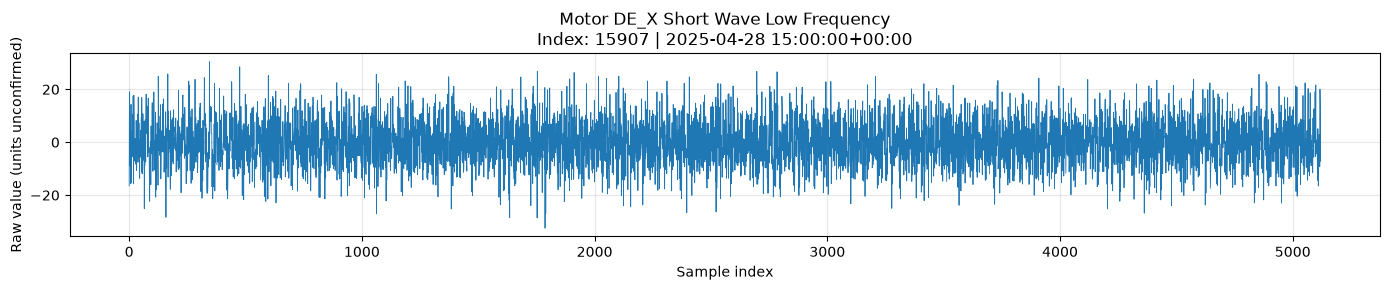

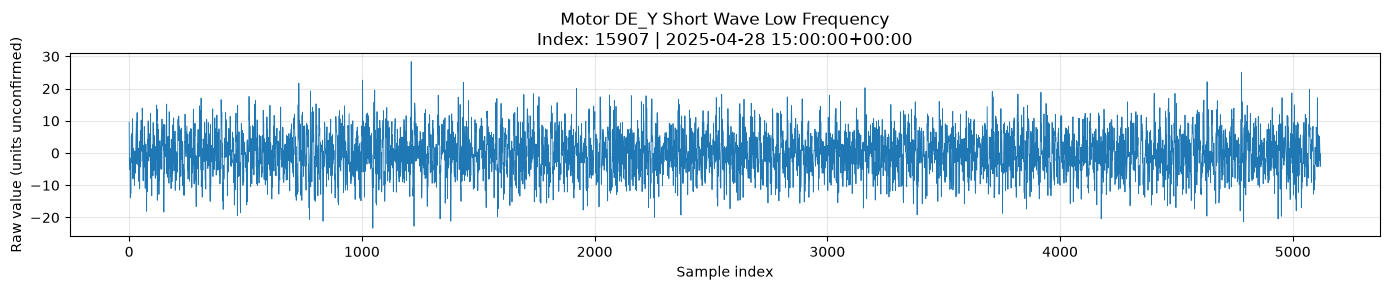

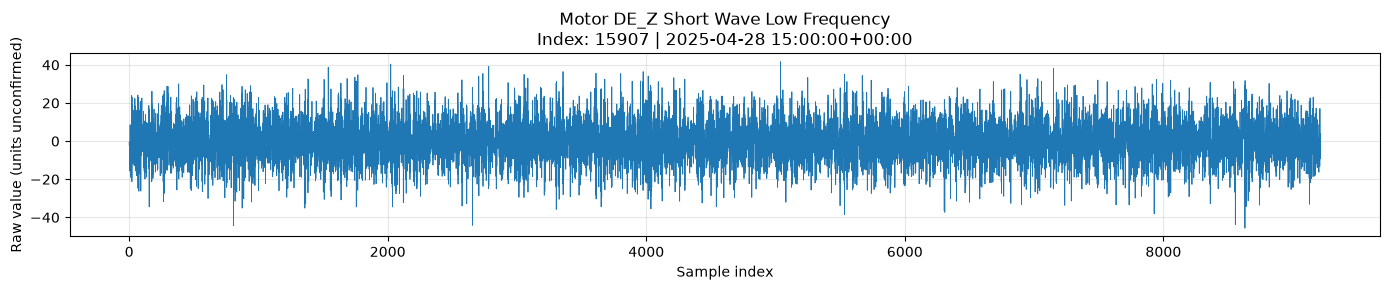

In [177]:
plot_waveforms(df_remaining, 15907)

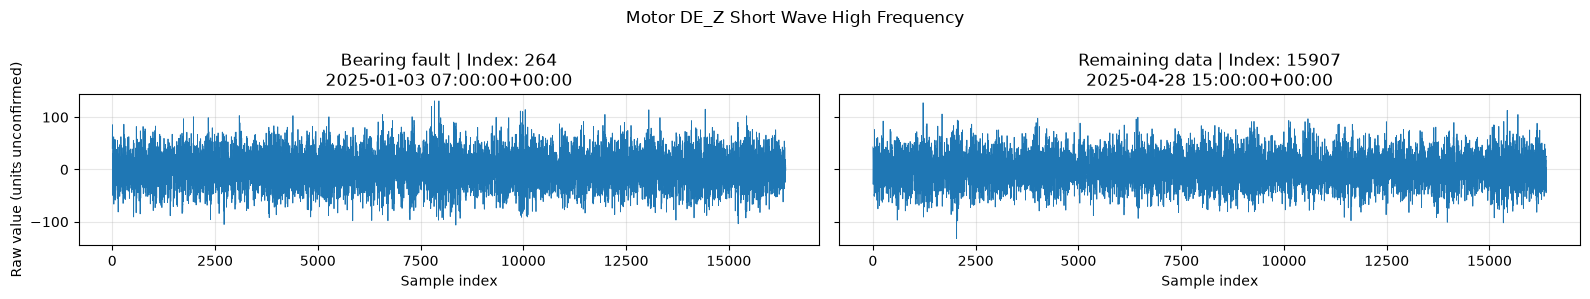

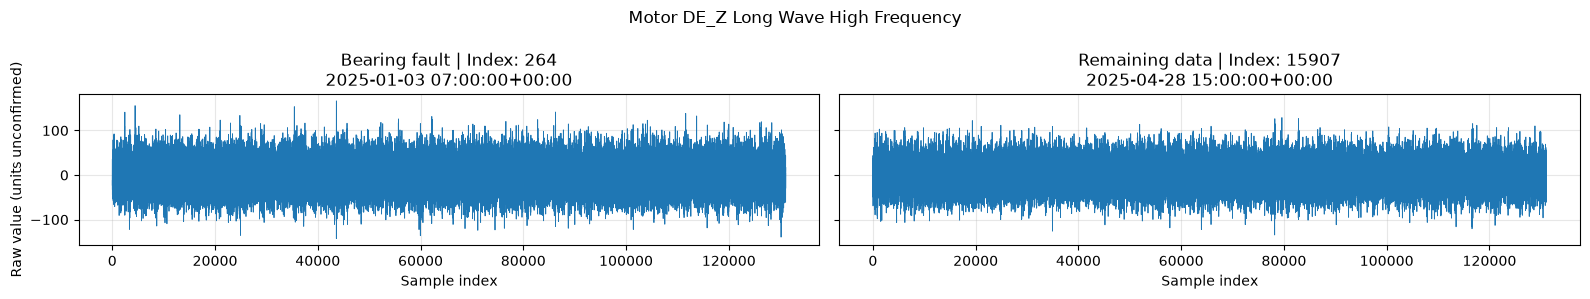

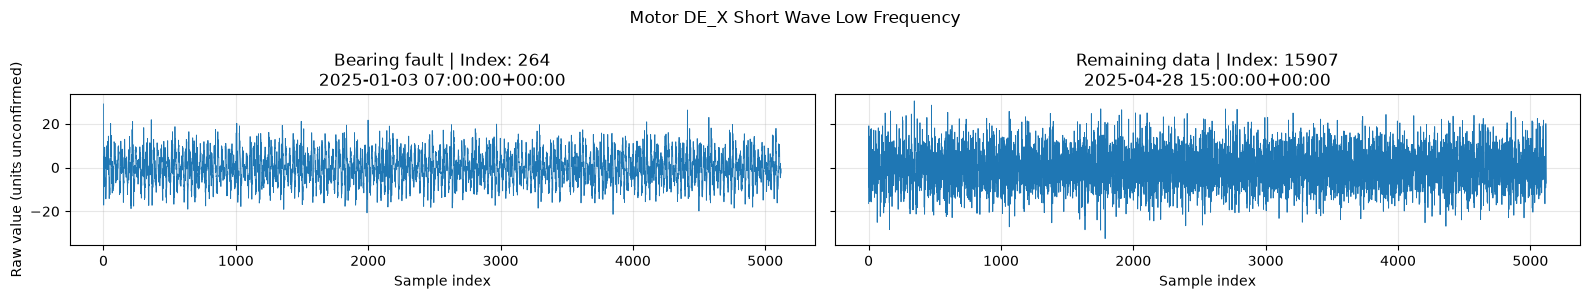

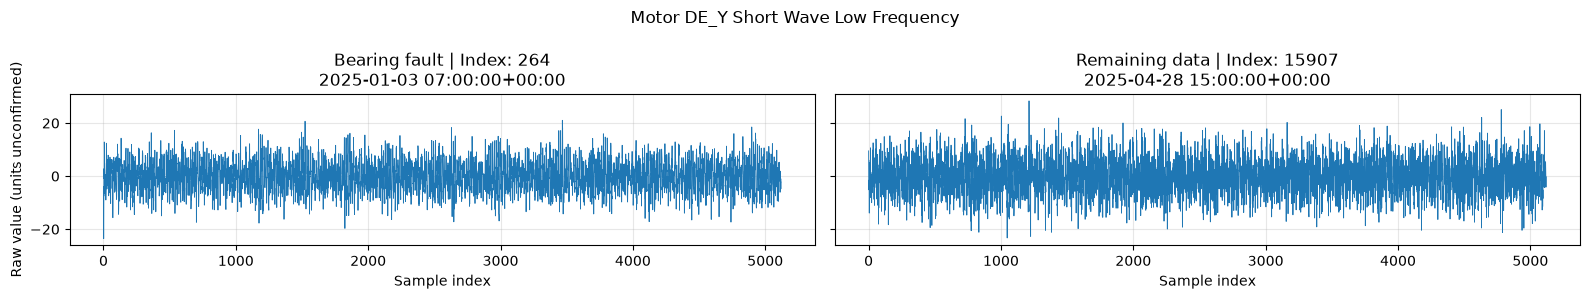

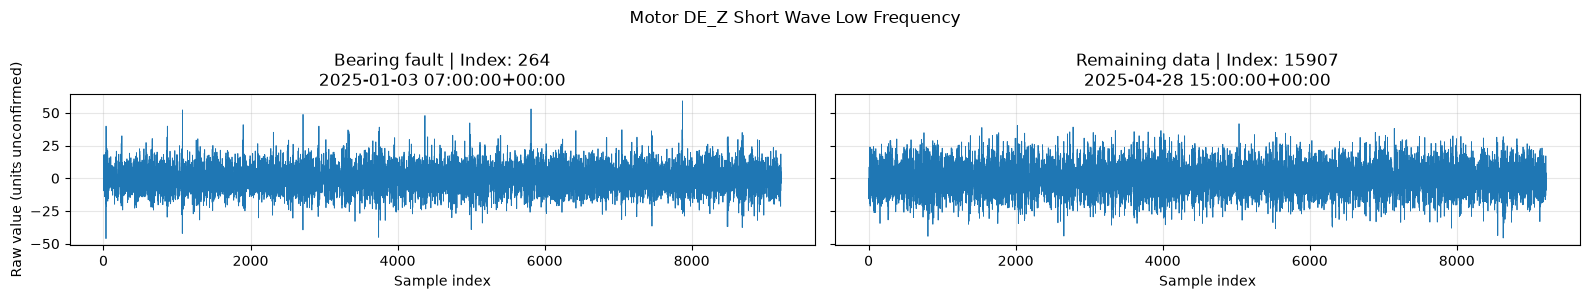

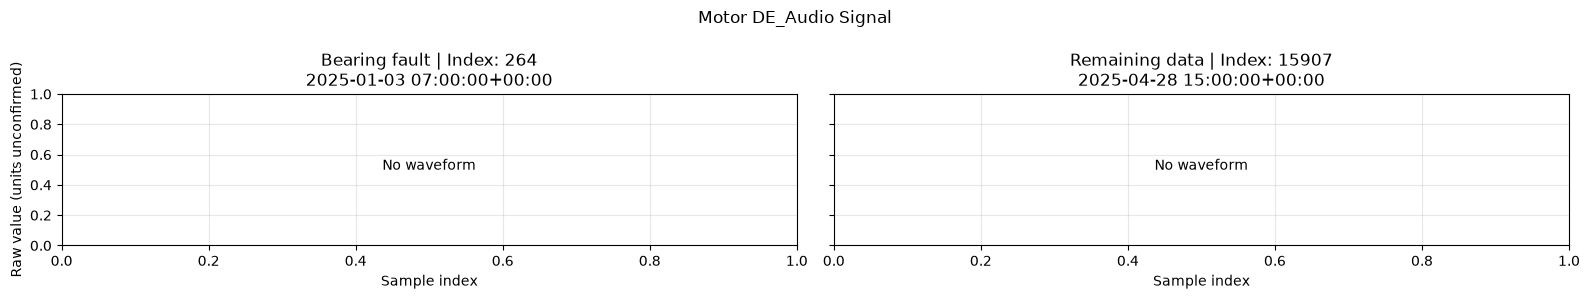

In [178]:
compare_waveforms(
    df_bearing, 264,
    df_remaining, 15907,
    labels=("Bearing fault", "Remaining data"),
)

In [181]:
comparison, summary = compare_reported_calculated_rms(df_bearing)
display(comparison.head())

No rows have both a valid waveform and reported RMS.


,row_index,reported_rms,calculated_rms,difference
